# Global Maritime Ports & Vessel Traffic Analysis

**Author:** Ludwig Schmiedler  
**Context:** TechAcademy Data Science with Python (Goethe University Frankfurt)  
**Objective:** Comprehensive analysis of global maritime shipping hubs, vessel count distributions, commodity throughput, and geospatial visualization.


# 1. Discovering the Data

## 1.1 Ports

In [5]:
# 1. How many variables does each data set have?
import pandas as pd
Ports.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8268 entries, 0 to 8267
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   portid                         8268 non-null   object
 1   fullname                       8268 non-null   object
 2   industry_top1                  8268 non-null   object
 3   industry_top2                  8022 non-null   object
 4   industry_top3                  7998 non-null   object
 5   share_country_maritime_import  8262 non-null   object
 6   share_country_maritime_export  8268 non-null   object
 7   LOCODE                         4512 non-null   object
 8   vessel_type                    8268 non-null   object
 9   vessel_count                   8268 non-null   int64 
dtypes: int64(1), object(9)
memory usage: 646.1+ KB


In [6]:
# 2. How many observations per variable do we have?

Ports.describe()

,vessel_count
count,8268.000000
mean,503.401427
std,2761.962065
min,0.000000
25%,5.000000
50%,69.000000
75%,285.000000
max,122404.000000


In [7]:
# 3. What do the variable names mean?
  # PortID = Nummer
  # Fullname = Name
  # Industry 1,2,3 = Was wird gehandelt
  # share_country_maritime_import = Anteil am Import
  # share_country_maritime_export = Anteil am Export
  # vessel_type = Container art
  # vessel_count = Container pro Schiff


In [8]:
# 4. What variable types are we dealing with? Boolean, numeric, character... ? (Code)

# 0   portid                         8268 non-null   object
# 1   fullname                       8268 non-null   object
# 2   industry_top1                  8268 non-null   object
# 3   industry_top2                  8022 non-null   object
# 4   industry_top3                  7998 non-null   object
# 5   share_country_maritime_import  8262 non-null   object --> Numeric (' Requires conversion to numeric)
# 6   share_country_maritime_export  8268 non-null   object --> Numeric (% Requires conversion to numeric)
# 7   LOCODE                         4512 non-null   object
# 8   vessel_type                    8268 non-null   object
# 9   vessel_count                   8268 non-null   int64  --> Numeric

ports_variable_types = Ports.dtypes
print(ports_variable_types)


portid                           object
fullname                         object
industry_top1                    object
industry_top2                    object
industry_top3                    object
share_country_maritime_import    object
share_country_maritime_export    object
LOCODE                           object
vessel_type                      object
vessel_count                      int64
dtype: object


In [9]:
# 5. Are there any mistakes with the variable types that might make future work difficult if not fixed?
Ports.head()
Ports.tail()


,portid,fullname,industry_top1,industry_top2,industry_top3,share_country_maritime_import,share_country_maritime_export,LOCODE,vessel_type,vessel_count
8263,port257,"Comodoro Rivadavia, Argentina","Petroleum, Chemical and Non-Metallic Mineral P...",Mining and Quarrying,Food & Beverages,3'88,3.63%,AR CRD,container,0
8264,port257,"Comodoro Rivadavia, Argentina","Petroleum, Chemical and Non-Metallic Mineral P...",Mining and Quarrying,Food & Beverages,3'88,3.63%,AR CRD,dry_bulk,0
8265,port257,"Comodoro Rivadavia, Argentina","Petroleum, Chemical and Non-Metallic Mineral P...",Mining and Quarrying,Food & Beverages,3'88,3.63%,AR CRD,general_cargo,2
8266,port257,"Comodoro Rivadavia, Argentina","Petroleum, Chemical and Non-Metallic Mineral P...",Mining and Quarrying,Food & Beverages,3'88,3.63%,AR CRD,RoRo,0
8267,port257,"Comodoro Rivadavia, Argentina","Petroleum, Chemical and Non-Metallic Mineral P...",Mining and Quarrying,Food & Beverages,3'88,3.63%,AR CRD,tanker,250


In [10]:
Ports.vessel_count.describe()

count      8268.000000
mean        503.401427
std        2761.962065
min           0.000000
25%           5.000000
50%          69.000000
75%         285.000000
max      122404.000000
Name: vessel_count, dtype: float64

## 1.2 Geographical Location

In [11]:
### 1. How many variables does each data set have?

print(Geographical_location)


geo_num_variables = Geographical_location.shape[1]
print(geo_num_variables)

                portname      country ISO3       continent   latitude  \
0             Tsuruga Ko        Japan  JPN  Asia & Pacific  35.667194   
1                Sibolga    Indonesia  IDN  Asia & Pacific   1.734969   
2             Fang-Cheng        China  CHN  Asia & Pacific  21.614205   
3                 Ube Ko        Japan  JPN  Asia & Pacific  33.944875   
4           Bluff Harbor  New Zealand  NZL  Asia & Pacific -46.590130   
...                  ...          ...  ...             ...        ...   
1373            Buchanan      Liberia  LBR          Africa   5.865644   
1374            Monrovia      Liberia  LBR          Africa   6.341982   
1375        Buenos Aires    Argentina  ARG   South America -34.619750   
1376             Campana    Argentina  ARG   South America -34.159425   
1377  Comodoro Rivadavia    Argentina  ARG   South America -45.833931   

             lon  
0     136.070611  
1      98.781715  
2     108.364339  
3     131.213184  
4     168.360216  
...      

In [12]:
### 2. How many observations per variable do we have?


Geographical_location.describe()


,latitude,lon
count,1378.000000,1378.000000
mean,24.551429,28.667910
std,26.339237,80.201278
min,-53.130331,-175.181170
25%,7.919353,-16.967879
50%,31.405617,17.524652
75%,43.405752,112.702309
max,70.661970,179.362926


In [13]:
### 3. What do the variable names mean?

print(Geographical_location.head())


       portname      country ISO3       continent   latitude         lon
0    Tsuruga Ko        Japan  JPN  Asia & Pacific  35.667194  136.070611
1       Sibolga    Indonesia  IDN  Asia & Pacific   1.734969   98.781715
2    Fang-Cheng        China  CHN  Asia & Pacific  21.614205  108.364339
3        Ube Ko        Japan  JPN  Asia & Pacific  33.944875  131.213184
4  Bluff Harbor  New Zealand  NZL  Asia & Pacific -46.590130  168.360216


In [14]:
### 4. What variable types are we dealing with? Boolean, numeric, character... ?

geo_variable_types = Geographical_location.dtypes
print(geo_variable_types)


portname      object
country       object
ISO3          object
continent     object
latitude     float64
lon          float64
dtype: object


In [15]:
### 5. Are there any mistakes with the variable types that might make future work difficult if not fixed?

Geographical_location.head()
Geographical_location.tail()

,portname,country,ISO3,continent,latitude,lon
1373,Buchanan,Liberia,LBR,Africa,5.865644,-10.044098
1374,Monrovia,Liberia,LBR,Africa,6.341982,-10.794029
1375,Buenos Aires,Argentina,ARG,South America,-34.619750,-58.352372
1376,Campana,Argentina,ARG,South America,-34.159425,-58.948031
1377,Comodoro Rivadavia,Argentina,ARG,South America,-45.833931,-67.449770


# 2. Data Cleaning & Transformation

## 2.1 Cleaning Ports Variables

In [16]:
Ports_CMI= Ports.share_country_maritime_import
print(Ports_CMI)

0        0'3
1        0'3
2        0'3
3        0'3
4        0'3
        ... 
8263    3'88
8264    3'88
8265    3'88
8266    3'88
8267    3'88
Name: share_country_maritime_import, Length: 8268, dtype: object


In [17]:
Ports_CMI_neu = Ports_CMI.str.replace("'", ".").astype(float)
print(Ports_CMI_neu)

0       0.30
1       0.30
2       0.30
3       0.30
4       0.30
        ... 
8263    3.88
8264    3.88
8265    3.88
8266    3.88
8267    3.88
Name: share_country_maritime_import, Length: 8268, dtype: float64


In [18]:
Ports_CME = Ports.share_country_maritime_export
print(Ports_CME)

0       0.09%
1       0.09%
2       0.09%
3       0.09%
4       0.09%
        ...  
8263    3.63%
8264    3.63%
8265    3.63%
8266    3.63%
8267    3.63%
Name: share_country_maritime_export, Length: 8268, dtype: object


In [19]:
Ports_CME_neu = Ports_CME.str.replace("%","").replace("NA","0").astype(float)
print(Ports_CME_neu)

0       0.09
1       0.09
2       0.09
3       0.09
4       0.09
        ... 
8263    3.63
8264    3.63
8265    3.63
8266    3.63
8267    3.63
Name: share_country_maritime_export, Length: 8268, dtype: float64


In [20]:
print(Ports)


        portid                       fullname  \
0     port1325              Tsuruga Ko, Japan   
1     port1325              Tsuruga Ko, Japan   
2     port1325              Tsuruga Ko, Japan   
3     port1325              Tsuruga Ko, Japan   
4     port1325              Tsuruga Ko, Japan   
...        ...                            ...   
8263   port257  Comodoro Rivadavia, Argentina   
8264   port257  Comodoro Rivadavia, Argentina   
8265   port257  Comodoro Rivadavia, Argentina   
8266   port257  Comodoro Rivadavia, Argentina   
8267   port257  Comodoro Rivadavia, Argentina   

                                          industry_top1         industry_top2  \
0     Petroleum, Chemical and Non-Metallic Mineral P...  Mining and Quarrying   
1     Petroleum, Chemical and Non-Metallic Mineral P...  Mining and Quarrying   
2     Petroleum, Chemical and Non-Metallic Mineral P...  Mining and Quarrying   
3     Petroleum, Chemical and Non-Metallic Mineral P...  Mining and Quarrying   
4     

## 2.2 Cleaning Geographical Location Variables

In [21]:
print(Geographical_location)


                portname      country ISO3       continent   latitude  \
0             Tsuruga Ko        Japan  JPN  Asia & Pacific  35.667194   
1                Sibolga    Indonesia  IDN  Asia & Pacific   1.734969   
2             Fang-Cheng        China  CHN  Asia & Pacific  21.614205   
3                 Ube Ko        Japan  JPN  Asia & Pacific  33.944875   
4           Bluff Harbor  New Zealand  NZL  Asia & Pacific -46.590130   
...                  ...          ...  ...             ...        ...   
1373            Buchanan      Liberia  LBR          Africa   5.865644   
1374            Monrovia      Liberia  LBR          Africa   6.341982   
1375        Buenos Aires    Argentina  ARG   South America -34.619750   
1376             Campana    Argentina  ARG   South America -34.159425   
1377  Comodoro Rivadavia    Argentina  ARG   South America -45.833931   

             lon  
0     136.070611  
1      98.781715  
2     108.364339  
3     131.213184  
4     168.360216  
...      

In [22]:
### latitude und longitute umbennen

Geographical_location.rename(columns={'latitude': 'lat'}, inplace=True)

Geographical_location.rename(columns={'lon': 'long'}, inplace=True)

print(Geographical_location)

                portname      country ISO3       continent        lat  \
0             Tsuruga Ko        Japan  JPN  Asia & Pacific  35.667194   
1                Sibolga    Indonesia  IDN  Asia & Pacific   1.734969   
2             Fang-Cheng        China  CHN  Asia & Pacific  21.614205   
3                 Ube Ko        Japan  JPN  Asia & Pacific  33.944875   
4           Bluff Harbor  New Zealand  NZL  Asia & Pacific -46.590130   
...                  ...          ...  ...             ...        ...   
1373            Buchanan      Liberia  LBR          Africa   5.865644   
1374            Monrovia      Liberia  LBR          Africa   6.341982   
1375        Buenos Aires    Argentina  ARG   South America -34.619750   
1376             Campana    Argentina  ARG   South America -34.159425   
1377  Comodoro Rivadavia    Argentina  ARG   South America -45.833931   

            long  
0     136.070611  
1      98.781715  
2     108.364339  
3     131.213184  
4     168.360216  
...      

In [23]:
print(Geographical_location)

                portname      country ISO3       continent        lat  \
0             Tsuruga Ko        Japan  JPN  Asia & Pacific  35.667194   
1                Sibolga    Indonesia  IDN  Asia & Pacific   1.734969   
2             Fang-Cheng        China  CHN  Asia & Pacific  21.614205   
3                 Ube Ko        Japan  JPN  Asia & Pacific  33.944875   
4           Bluff Harbor  New Zealand  NZL  Asia & Pacific -46.590130   
...                  ...          ...  ...             ...        ...   
1373            Buchanan      Liberia  LBR          Africa   5.865644   
1374            Monrovia      Liberia  LBR          Africa   6.341982   
1375        Buenos Aires    Argentina  ARG   South America -34.619750   
1376             Campana    Argentina  ARG   South America -34.159425   
1377  Comodoro Rivadavia    Argentina  ARG   South America -45.833931   

            long  
0     136.070611  
1      98.781715  
2     108.364339  
3     131.213184  
4     168.360216  
...      

In [24]:
### Alle relevanten Columns in numeric or character type umwandeln


Geographical_location['portname'] = Geographical_location['portname'].astype(str)
Geographical_location['country'] = Geographical_location['country'].astype(str)
Geographical_location['ISO3'] = Geographical_location['ISO3'].astype(str)
Geographical_location['continent'] = Geographical_location['continent'].astype(str)
Geographical_location['lat'] = Geographical_location['lat'].astype(str)
Geographical_location['long'] = Geographical_location['long'].astype(str)

geo_variable_types = Geographical_location.dtypes
print(geo_variable_types)


portname     object
country      object
ISO3         object
continent    object
lat          object
long         object
dtype: object


In [25]:
print(Ports.dtypes)

Ports['vessel_count'] = Ports['vessel_count'].astype(str)

print(Ports.dtypes)

portid                           object
fullname                         object
industry_top1                    object
industry_top2                    object
industry_top3                    object
share_country_maritime_import    object
share_country_maritime_export    object
LOCODE                           object
vessel_type                      object
vessel_count                      int64
dtype: object
portid                           object
fullname                         object
industry_top1                    object
industry_top2                    object
industry_top3                    object
share_country_maritime_import    object
share_country_maritime_export    object
LOCODE                           object
vessel_type                      object
vessel_count                     object
dtype: object


# 3. Discovering Ports

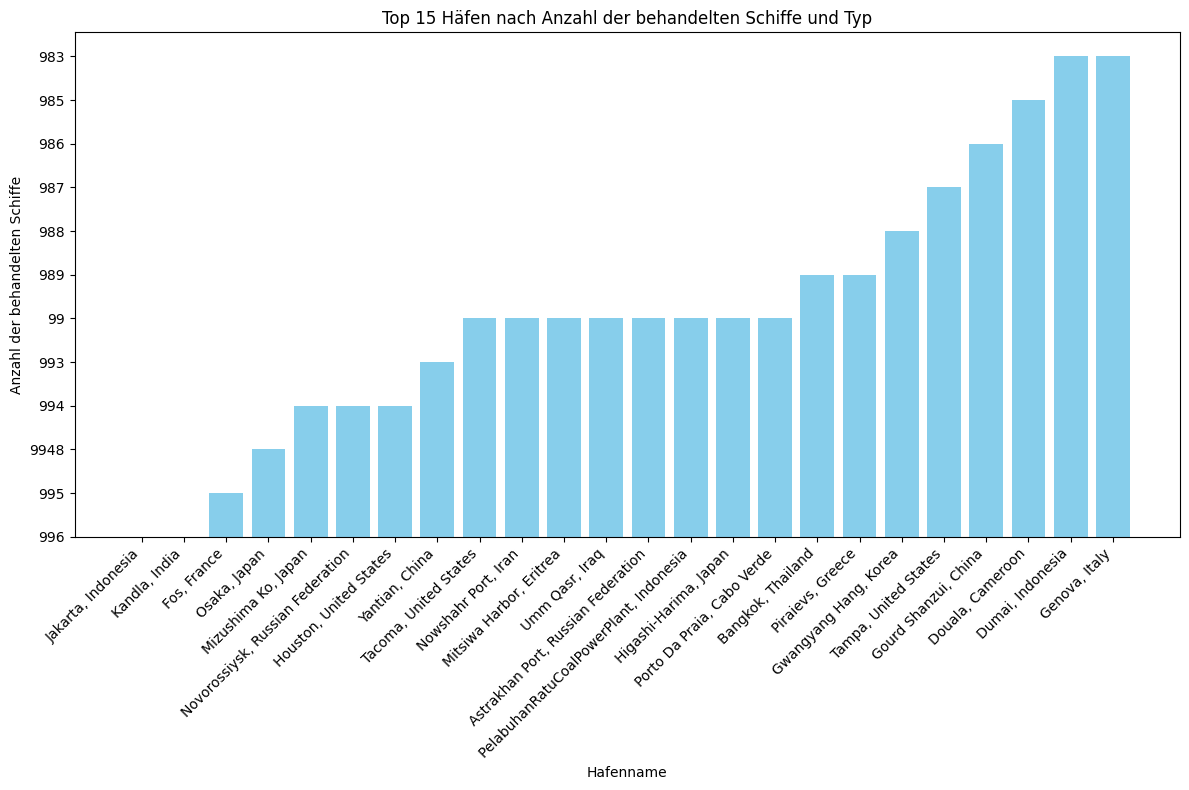

In [26]:
import matplotlib.pyplot as plt

top_15_ports = Ports.sort_values(by='vessel_count', ascending=False).head(24
                                                                          )
plt.figure(figsize=(12, 8))
plt.bar(top_15_ports['fullname'], top_15_ports['vessel_count'], color='skyblue')
plt.xlabel('Hafenname')
plt.ylabel('Anzahl der behandelten Schiffe')
plt.title('Top 15 Ports by Handled Vessels and Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Reshaping Data

In [27]:
### Anzahl verschieden Schiffsarten

unique_vessel_types = Ports['vessel_type'].nunique()
print(f"Anzahl der verschiedenen Schiffstypen: {unique_vessel_types}")

Anzahl der verschiedenen Schiffstypen: 6


In [28]:
### Daten in langes Format umformen
Ports_lang = Ports.pivot_table(index=['portid','fullname', 'industry_top1', 'industry_top2', 'industry_top3', 'share_country_maritime_import', 'share_country_maritime_export','LOCODE'], columns='vessel_type', values='vessel_count')
Ports_lang.reset_index(inplace=True)


In [29]:
### Vergleich der Anzahl von Zeilen vor und nach der Umformung

print(f"Anzahl der Zeilen vor der Umformung: {len(Ports)}")
print(f"Anzahl der Zeilen nach der Umformung: {len(Ports_lang)}")


Anzahl der Zeilen vor der Umformung: 8268
Anzahl der Zeilen nach der Umformung: 730


In [30]:
### Vergleich der Anzahl der einzigartigen vessel_type

unique_vessel_types_lang = Ports_lang.columns[1:]
print(f"Einzigartige Schiffstypen nach der Umformung: {len(unique_vessel_types_lang)}")


print("\nOverview of Reshaped Data (Long Format):")
print(Ports_lang)

Einzigartige Schiffstypen nach der Umformung: 13

Übersicht der umgeformten Daten (lange Form):
vessel_type    portid                  fullname  \
0               port0    Abbot Point, Australia   
1               port1           Abenra, Denmark   
2              port10           Agadir, Morocco   
3            port1009  Porto Grande, Cabo Verde   
4             port101            Balboa, Panama   
..                ...                       ...   
725           port984        Port of Duqm, Oman   
726            port99            Bakar, Croatia   
727           port992       Portland, Australia   
728           port993   Portland, United States   
729           port997      Porto Alegre, Brazil   

vessel_type                                      industry_top1  \
0                                         Mining and Quarrying   
1            Petroleum, Chemical and Non-Metallic Mineral P...   
2            Petroleum, Chemical and Non-Metallic Mineral P...   
3            Petroleum, Che

# 5. Merging Data Sets

In [31]:
Ports = Ports_lang

print(Ports.head())


vessel_type    portid                  fullname  \
0               port0    Abbot Point, Australia   
1               port1           Abenra, Denmark   
2              port10           Agadir, Morocco   
3            port1009  Porto Grande, Cabo Verde   
4             port101            Balboa, Panama   

vessel_type                                      industry_top1  \
0                                         Mining and Quarrying   
1            Petroleum, Chemical and Non-Metallic Mineral P...   
2            Petroleum, Chemical and Non-Metallic Mineral P...   
3            Petroleum, Chemical and Non-Metallic Mineral P...   
4            Petroleum, Chemical and Non-Metallic Mineral P...   

vessel_type                                      industry_top2  \
0            Petroleum, Chemical and Non-Metallic Mineral P...   
1                                         Mining and Quarrying   
2                                         Mining and Quarrying   
3                               

In [32]:
# Split fullname column into port name and country

Ports[['portname', 'country']] = Ports['fullname'].str.split(',', n=1, expand=True).applymap(str.strip)
print(Ports.head())

vessel_type    portid                  fullname  \
0               port0    Abbot Point, Australia   
1               port1           Abenra, Denmark   
2              port10           Agadir, Morocco   
3            port1009  Porto Grande, Cabo Verde   
4             port101            Balboa, Panama   

vessel_type                                      industry_top1  \
0                                         Mining and Quarrying   
1            Petroleum, Chemical and Non-Metallic Mineral P...   
2            Petroleum, Chemical and Non-Metallic Mineral P...   
3            Petroleum, Chemical and Non-Metallic Mineral P...   
4            Petroleum, Chemical and Non-Metallic Mineral P...   

vessel_type                                      industry_top2  \
0            Petroleum, Chemical and Non-Metallic Mineral P...   
1                                         Mining and Quarrying   
2                                         Mining and Quarrying   
3                               

In [33]:
# Drop fullname column

Ports.drop(columns=['fullname'], inplace = True)
print(Ports)

vessel_type    portid                                      industry_top1  \
0               port0                               Mining and Quarrying   
1               port1  Petroleum, Chemical and Non-Metallic Mineral P...   
2              port10  Petroleum, Chemical and Non-Metallic Mineral P...   
3            port1009  Petroleum, Chemical and Non-Metallic Mineral P...   
4             port101  Petroleum, Chemical and Non-Metallic Mineral P...   
..                ...                                                ...   
725           port984                               Mining and Quarrying   
726            port99                                   Food & Beverages   
727           port992                                        Agriculture   
728           port993  Petroleum, Chemical and Non-Metallic Mineral P...   
729           port997  Petroleum, Chemical and Non-Metallic Mineral P...   

vessel_type                                      industry_top2  \
0            Petroleu

In [34]:
merge_df = pd.merge(Ports, Geographical_location, on=['portname', 'country'], how='inner')
data = merge_df
print(data)


       portid                                      industry_top1  \
0       port0                               Mining and Quarrying   
1       port1  Petroleum, Chemical and Non-Metallic Mineral P...   
2      port10  Petroleum, Chemical and Non-Metallic Mineral P...   
3    port1009  Petroleum, Chemical and Non-Metallic Mineral P...   
4     port101  Petroleum, Chemical and Non-Metallic Mineral P...   
..        ...                                                ...   
689   port981                               Mining and Quarrying   
690    port99                                   Food & Beverages   
691   port992                                        Agriculture   
692   port993  Petroleum, Chemical and Non-Metallic Mineral P...   
693   port997  Petroleum, Chemical and Non-Metallic Mineral P...   

                                         industry_top2         industry_top3  \
0    Petroleum, Chemical and Non-Metallic Mineral P...      Food & Beverages   
1                      

# 6. Domestically Significant Ports

In [35]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 694 entries, 0 to 693
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   portid                         694 non-null    object
 1   industry_top1                  694 non-null    object
 2   industry_top2                  694 non-null    object
 3   industry_top3                  694 non-null    object
 4   share_country_maritime_import  694 non-null    object
 5   share_country_maritime_export  694 non-null    object
 6   LOCODE                         694 non-null    object
 7   RoRo                           694 non-null    object
 8   container                      694 non-null    object
 9   dry_bulk                       694 non-null    object
 10  general_cargo                  694 non-null    object
 11  tanker                         694 non-null    object
 12  total                          694 non-null    object
 13  portn

In [36]:
# Den Anteil der Importe in numerische Werte umwandeln
data['share_country_maritime_import'] = data['share_country_maritime_import'].str.replace("'", ".").astype(float)

In [37]:
# Function to identify domestically significant ports
def determine_significant_ports(group):
    group = group.sort_values('share_country_maritime_import', ascending=False)
    group['cumulative_import'] = group['share_country_maritime_import'].cumsum()
    group['domestically_significant'] = (group['cumulative_import'] <= 80).astype(int)
    return group

# Anwendung der Funktion auf jedes Land
data = data.groupby('country').apply(determine_significant_ports)


In [38]:
# Count domestically significant vs. non-significant ports
num_significant_ports = data['domestically_significant'].sum()
num_not_significant_ports = len(data) - num_significant_ports

num_significant_ports, num_not_significant_ports

(493, 201)

In [39]:
print(data["share_country_maritime_import"])

country     
Albania  321    91.01
Algeria  630    21.39
         308    13.16
         441     7.86
         576     2.41
                ...  
Vietnam  295     3.23
         33      1.26
         193     0.73
         609     0.40
Yemen    649    55.36
Name: share_country_maritime_import, Length: 694, dtype: float64


# 7. Top Industries

In [40]:
data.head()

portid                                      industry_top1  \
country                                                                   
Albania 321  port312                               Mining and Quarrying   
Algeria 630  port856                                        Agriculture   
        308  port293  Petroleum, Chemical and Non-Metallic Mineral P...   
        441   port53                                        Agriculture   
        576  port771  Petroleum, Chemical and Non-Metallic Mineral P...   

                                                 industry_top2  \
country                                                          
Albania 321  Petroleum, Chemical and Non-Metallic Mineral P...   
Algeria 630  Petroleum, Chemical and Non-Metallic Mineral P...   
        308                               Mining and Quarrying   
        441                               Mining and Quarrying   
        576                               Mining and Quarrying   

                industry_top3  share_country_maritime_import  \
country                                                        
Albania 321  Food & Beverages                          91.01   
Algeria 630  Food & Beverages                          21.39   
        308    Metal Products                          13.16   
        441  Food & Beverages                           7.86   
        576       Agriculture                           2.41   

            share_country_maritime_export  LOCODE  RoRo container dry_bulk  \
country                                                                      
Albania 321                        98.85%  AL DRZ   2.0      35.0     22.0   
Algeria 630                         4.57%  DZ ORN   8.0     198.0    245.0   
        308                         8.27%  DZ DJE   7.0      38.0    112.0   
        441                         6.74%  DZ AAE   0.0     103.0    108.0   
        576                         0.75%  DZ MOS  20.0      26.0     34.0   

             ... tanker  total    portname  country ISO3 continent  \
country      ...                                                     
Albania 321  ...   53.0  219.0      Durres  Albania  ALB    Europe   
Algeria 630  ...   54.0  684.0        Oran  Algeria  DZA    Africa   
        308  ...   11.0  246.0   Djen-Djen  Algeria  DZA    Africa   
        441  ...    7.0  332.0      Annaba  Algeria  DZA    Africa   
        576  ...    7.0  212.0  Mostaganem  Algeria  DZA    Africa   

                     lat          long cumulative_import  \
country                                                    
Albania 321  41.34064126    19.4439999             91.01   
Algeria 630  35.71085451  -0.638375154             21.39   
        308  36.82059245   5.886895265             34.55   
        441  36.89622629    7.76762179             42.41   
        576  35.93460181   0.076892121             44.82   

             domestically_significant  
country                                
Albania 321                         0  
Algeria 630                         1  
        308                         1  
        441                         1  
        576                         1  

[5 rows x 21 columns]

In [41]:
# Combine top industry columns
top_industries = pd.concat([data['industry_top1'], data['industry_top2'], data['industry_top3']])





In [42]:
# Calculate industry frequencies
industry_counts = top_industries.value_counts()

In [43]:
# Einzigartige Werte in den Top-Industrie-Spalten
unique_industry_top1 = data['industry_top1'].nunique()
unique_industry_top2 = data['industry_top2'].nunique()
unique_industry_top3 = data['industry_top3'].nunique()

print(f"Einzigartige Werte in industry_top1: {unique_industry_top1}")
print(f"Einzigartige Werte in industry_top2: {unique_industry_top2}")
print(f"Einzigartige Werte in industry_top3: {unique_industry_top3}")


Einzigartige Werte in industry_top1: 7
Einzigartige Werte in industry_top2: 10
Einzigartige Werte in industry_top3: 10


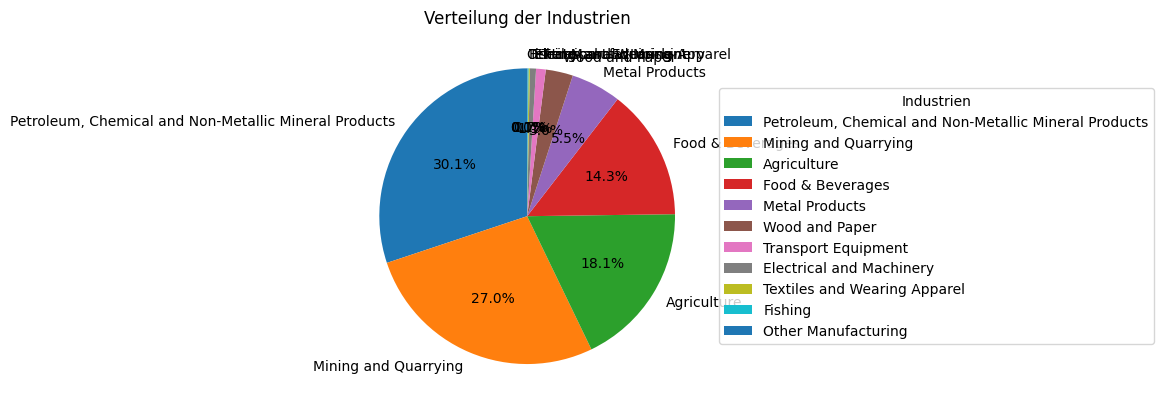

In [44]:
import matplotlib.pyplot as plt

# Plot-Daten vorbereiten
labels = industry_counts.index
sizes = industry_counts.values

# Tortendiagramm erstellen
fig, ax = plt.subplots()
wedges, texts, autotexts = ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

# Add legend
ax.legend(wedges, labels, title="Industrien", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

# Add title
plt.title("Verteilung der Industrien")

# Diagramm anzeigen
plt.show()

# 8. Mapping It Out

In [45]:
data.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 694 entries, ('Albania', 321) to ('Yemen', 649)
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   portid                         694 non-null    object 
 1   industry_top1                  694 non-null    object 
 2   industry_top2                  694 non-null    object 
 3   industry_top3                  694 non-null    object 
 4   share_country_maritime_import  694 non-null    float64
 5   share_country_maritime_export  694 non-null    object 
 6   LOCODE                         694 non-null    object 
 7   RoRo                           694 non-null    object 
 8   container                      694 non-null    object 
 9   dry_bulk                       694 non-null    object 
 10  general_cargo                  694 non-null    object 
 11  tanker                         694 non-null    object 
 12  total                   

In [46]:
import plotly.express as px

if 'lat' in data.columns and 'long' in data.columns and 'portname' in data.columns:

    fig = px.scatter_geo(data,
                         lat='lat',
                         lon='long',
                         hover_name='portname',

                         title='Global Maritime Ports Distribution')

    # Display interactive map
    fig.show()

#9. Surprise US!

In [47]:
required_columns = ['lat', 'long', 'portname', 'industry_top1']
if all(col in data.columns for col in required_columns):

    fig = px.scatter_geo(data,
                         lat='lat',
                         lon='long',
                         color='industry_top1',
                         hover_name='portname',
                         hover_data={'industry_top1': True,
                                     'lat': False,
                                     'long': False},
                         title='Global Maritime Ports Distribution')


    fig.show()



conclusion = (
    "By incorporating industry_top1, we can identify the primary commercial cargo "
    "handled at each major port globally."
)
print(conclusion)
